In [195]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
from IPython.display import display
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression, LinearRegression
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, ConfusionMatrixDisplay, mean_absolute_error, mean_squared_error, r2_score, f1_score, recall_score, precision_score
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import GridSearchCV

In [103]:
pd.set_option('display.max_columns', None)
df=pd.read_csv('data.csv',sep=';')
df

,Marital status,Application mode,Application order,Course,Daytime/evening attendance\t,Previous qualification,Previous qualification (grade),Nacionality,Mother's qualification,Father's qualification,Mother's occupation,Father's occupation,Admission grade,Displaced,Educational special needs,Debtor,Tuition fees up to date,Gender,Scholarship holder,Age at enrollment,International,Curricular units 1st sem (credited),Curricular units 1st sem (enrolled),Curricular units 1st sem (evaluations),Curricular units 1st sem (approved),Curricular units 1st sem (grade),Curricular units 1st sem (without evaluations),Curricular units 2nd sem (credited),Curricular units 2nd sem (enrolled),Curricular units 2nd sem (evaluations),Curricular units 2nd sem (approved),Curricular units 2nd sem (grade),Curricular units 2nd sem (without evaluations),Unemployment rate,Inflation rate,GDP,Target
0,1,17,5,171,1,1,122.0,1,19,12,5,9,127.3,1,0,0,1,1,0,20,0,0,0,0,0,0.000000,0,0,0,0,0,0.000000,0,10.8,1.4,1.74,Dropout
1,1,15,1,9254,1,1,160.0,1,1,3,3,3,142.5,1,0,0,0,1,0,19,0,0,6,6,6,14.000000,0,0,6,6,6,13.666667,0,13.9,-0.3,0.79,Graduate
2,1,1,5,9070,1,1,122.0,1,37,37,9,9,124.8,1,0,0,0,1,0,19,0,0,6,0,0,0.000000,0,0,6,0,0,0.000000,0,10.8,1.4,1.74,Dropout
3,1,17,2,9773,1,1,122.0,1,38,37,5,3,119.6,1,0,0,1,0,0,20,0,0,6,8,6,13.428571,0,0,6,10,5,12.400000,0,9.4,-0.8,-3.12,Graduate
4,2,39,1,8014,0,1,100.0,1,37,38,9,9,141.5,0,0,0,1,0,0,45,0,0,6,9,5,12.333333,0,0,6,6,6,13.000000,0,13.9,-0.3,0.79,Graduate
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4419,1,1,6,9773,1,1,125.0,1,1,1,5,4,122.2,0,0,0,1,1,0,19,0,0,6,7,5,13.600000,0,0,6,8,5,12.666667,0,15.5,2.8,-4.06,Graduate
4420,1,1,2,9773,1,1,120.0,105,1,1,9,9,119.0,1,0,1,0,0,0,18,1,0,6,6,6,12.000000,0,0,6,6,2,11.000000,0,11.1,0.6,2.02,Dropout
4421,1,1,1,9500,1,1,154.0,1,37,37,9,9,149.5,1,0,0,1,0,1,30,0,0,7,8,7,14.912500,0,0,8,9,1,13.500000,0,13.9,-0.3,0.79,Dropout
4422,1,1,1,9147,1,1,180.0,1,37,37,7,4,153.8,1,0,0,1,0,1,20,0,0,5,5,5,13.800000,0,0,5,6,5,12.000000,0,9.4,-0.8,-3.12,Graduate


In [104]:
print(f"Shape: {df.shape}, \nDatatype:\n{df.dtypes}, \nColumns list: {df.columns.tolist()}, \n{df.isnull().sum()}, \n{df.duplicated().sum()}")

Shape: (4424, 37), 
Datatype:
Marital status                                      int64
Application mode                                    int64
Application order                                   int64
Course                                              int64
Daytime/evening attendance\t                        int64
Previous qualification                              int64
Previous qualification (grade)                    float64
Nacionality                                         int64
Mother's qualification                              int64
Father's qualification                              int64
Mother's occupation                                 int64
Father's occupation                                 int64
Admission grade                                   float64
Displaced                                           int64
Educational special needs                           int64
Debtor                                              int64
Tuition fees up to date                   

In [105]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 4424 entries, 0 to 4423
Data columns (total 37 columns):
 #   Column                                          Non-Null Count  Dtype  
---  ------                                          --------------  -----  
 0   Marital status                                  4424 non-null   int64  
 1   Application mode                                4424 non-null   int64  
 2   Application order                               4424 non-null   int64  
 3   Course                                          4424 non-null   int64  
 4   Daytime/evening attendance	                     4424 non-null   int64  
 5   Previous qualification                          4424 non-null   int64  
 6   Previous qualification (grade)                  4424 non-null   float64
 7   Nacionality                                     4424 non-null   int64  
 8   Mother's qualification                          4424 non-null   int64  
 9   Father's qualification                          4424

Target
Graduate    2209
Dropout     1421
Enrolled     794
Name: count, dtype: int64 
 Target
Graduate    49.932188
Dropout     32.120253
Enrolled    17.947559
Name: proportion, dtype: float64


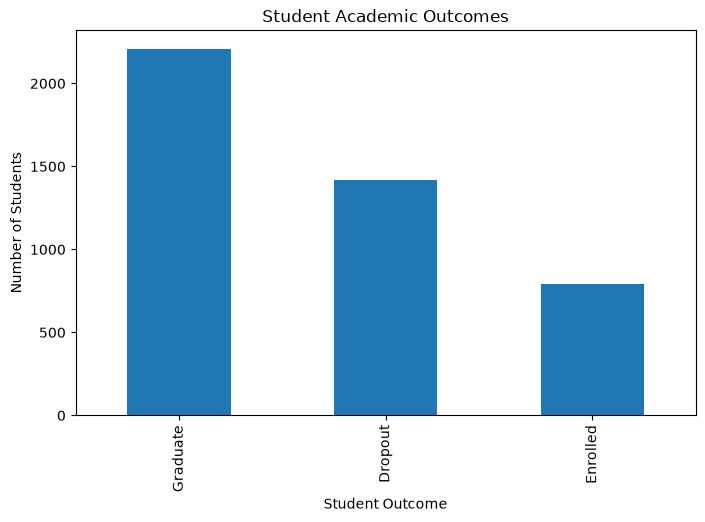

In [106]:
print(df['Target'].value_counts(),"\n",df['Target'].value_counts(normalize=True) * 100)

df['Target'].value_counts().plot(
    kind='bar',
    figsize=(8, 5),
    title='Student Academic Outcomes'
)
plt.xlabel('Student Outcome')
plt.ylabel('Number of Students')
plt.show()

In [107]:
continuous_cols = [
    'Previous qualification (grade)',
    'Admission grade',
    'Age at enrollment',
    'Curricular units 1st sem (grade)',
    'Curricular units 2nd sem (grade)',
    'Unemployment rate',
    'Inflation rate',
    'GDP'
]
missing_cols = [col for col in continuous_cols if col not in df.columns]
if missing_cols:
    print("Columns not found:", missing_cols)
else:
    print("All selected columns are available")

All selected columns are available


In [108]:
summary = df[continuous_cols].agg(
    ['mean', 'median', 'std', 'min', 'max']
).T
summary.round(2)

,mean,median,std,min,max
Previous qualification (grade),132.61,133.10,13.19,95.00,190.00
Admission grade,126.98,126.10,14.48,95.00,190.00
Age at enrollment,23.27,20.00,7.59,17.00,70.00
Curricular units 1st sem (grade),10.64,12.29,4.84,0.00,18.88
Curricular units 2nd sem (grade),10.23,12.20,5.21,0.00,18.57
Unemployment rate,11.57,11.10,2.66,7.60,16.20
Inflation rate,1.23,1.40,1.38,-0.80,3.70
GDP,0.00,0.32,2.27,-4.06,3.51


In [109]:
for col in continuous_cols:
    values = df[col].dropna().to_numpy()

    q1, q3 = np.percentile(values, [25, 75])
    iqr = round((q3 - q1),2)

    print(f"{col}: Q1={q1}, Q3={q3}, IQR={iqr}")

Previous qualification (grade): Q1=125.0, Q3=140.0, IQR=15.0
Admission grade: Q1=117.9, Q3=134.8, IQR=16.9
Age at enrollment: Q1=19.0, Q3=25.0, IQR=6.0
Curricular units 1st sem (grade): Q1=11.0, Q3=13.4, IQR=2.4
Curricular units 2nd sem (grade): Q1=10.75, Q3=13.333333333333334, IQR=2.58
Unemployment rate: Q1=9.4, Q3=13.9, IQR=4.5
Inflation rate: Q1=0.3, Q3=2.6, IQR=2.3
GDP: Q1=-1.7, Q3=1.79, IQR=3.49


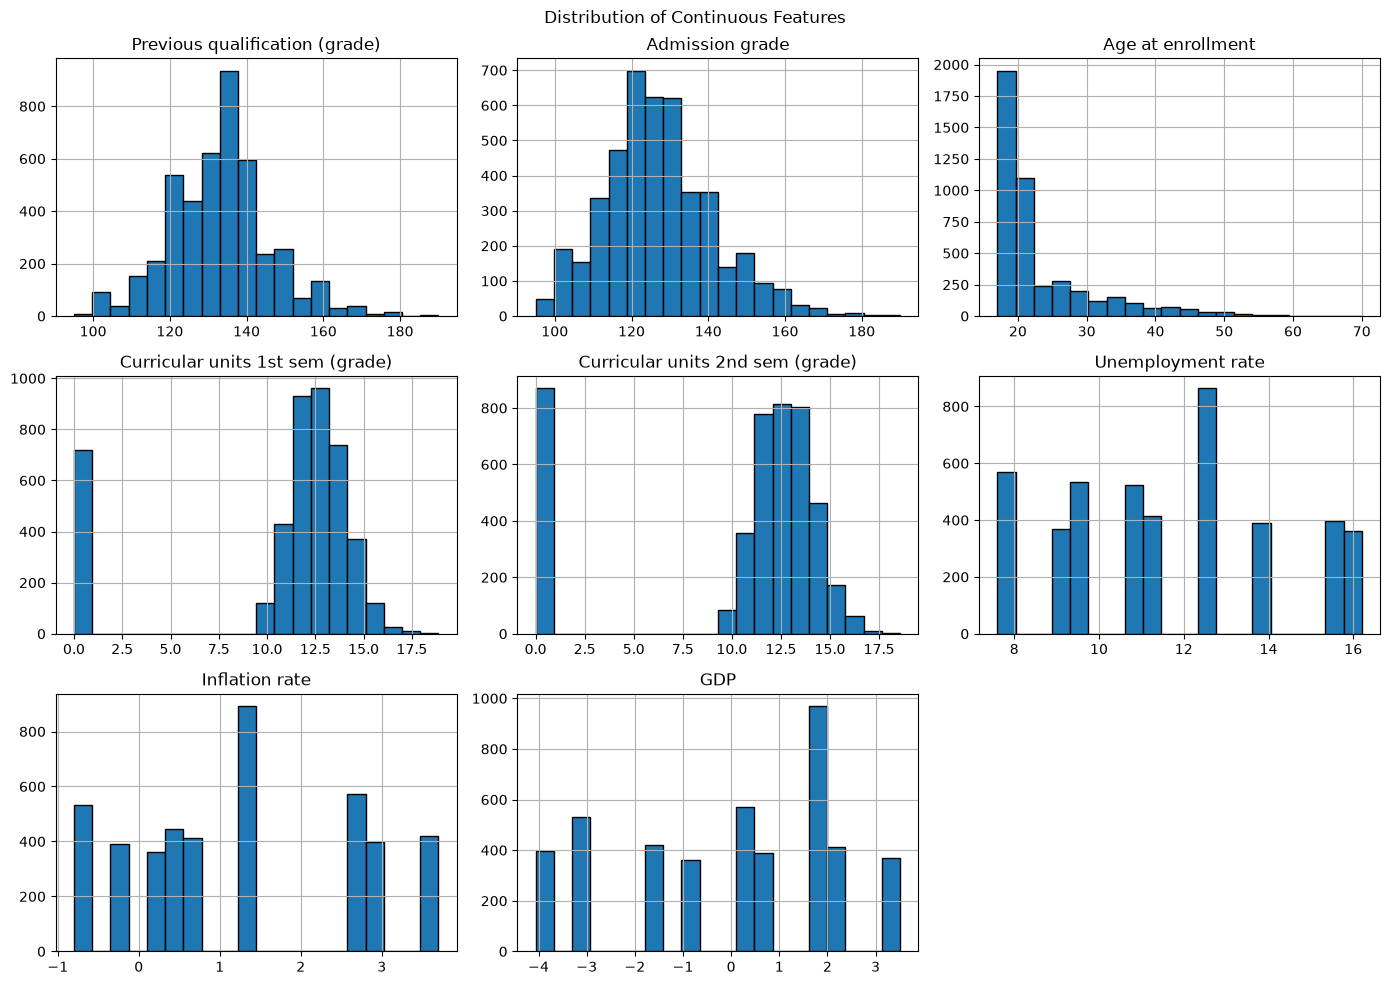

In [110]:
df[continuous_cols].hist(
    figsize=(14, 10),
    bins=20,
    edgecolor='black'
)

plt.suptitle('Distribution of Continuous Features')
plt.tight_layout()
plt.show()

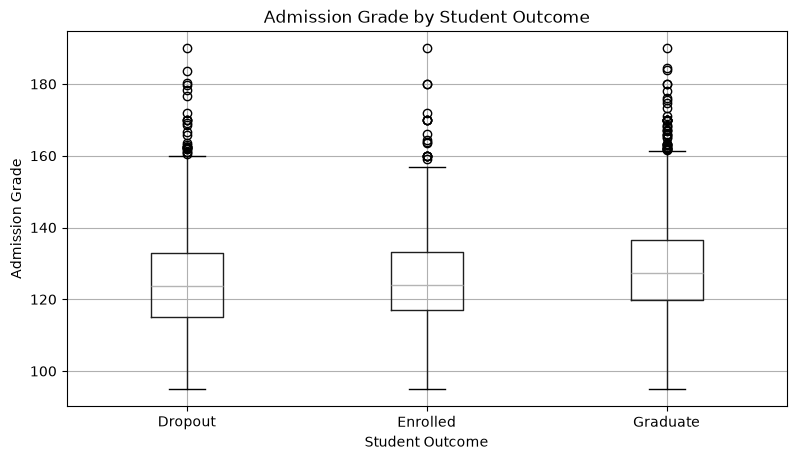

In [111]:
df.boxplot(
    column='Admission grade',
    by='Target',
    figsize=(9, 5)
)

plt.title('Admission Grade by Student Outcome')
plt.suptitle('')
plt.xlabel('Student Outcome')
plt.ylabel('Admission Grade')
plt.show()

,Admission grade,Curricular units 1st sem (grade),Curricular units 1st sem (approved),Curricular units 1st sem (enrolled)
Target,,,,
Dropout,124.96,7.26,2.55,5.82
Enrolled,125.53,11.13,4.32,5.96
Graduate,128.79,12.64,6.23,6.67


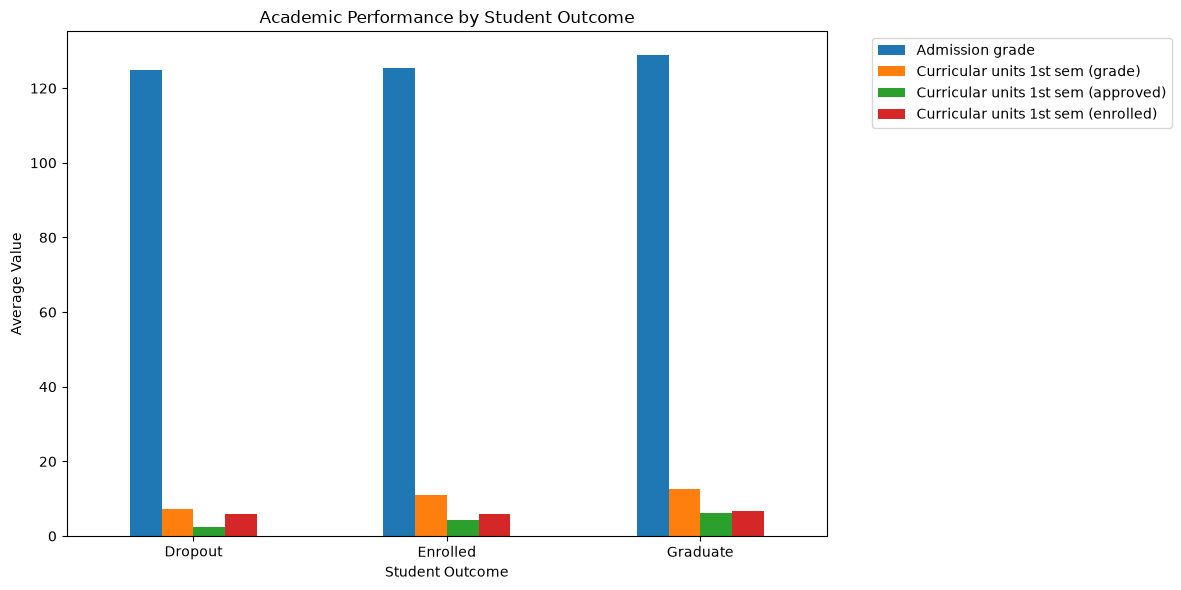

In [112]:
performance = df.groupby('Target')[
    [
        'Admission grade',
        'Curricular units 1st sem (grade)',
        'Curricular units 1st sem (approved)',
        'Curricular units 1st sem (enrolled)'
    ]
].mean()
display(performance.round(2))
performance.plot(
    kind='bar',
    figsize=(12, 6)
)

plt.title('Academic Performance by Student Outcome')
plt.xlabel('Student Outcome')
plt.ylabel('Average Value')
plt.xticks(rotation=0)
plt.legend(bbox_to_anchor=(1.05, 1))
plt.tight_layout()
plt.show()

In [113]:
zero_grades = df[
    df['Curricular units 1st sem (grade)'] == 0
]

print("Total zero grades:", len(zero_grades))

print("\nOutcome distribution:")
print(zero_grades['Target'].value_counts())

Total zero grades: 718

Outcome distribution:
Target
Dropout     570
Graduate     77
Enrolled     71
Name: count, dtype: int64


Target,Dropout,Enrolled,Graduate
Scholarship holder,,,
0,1287,664,1374
1,134,130,835


Target,Dropout,Enrolled,Graduate
Scholarship holder,,,
0,38.71,19.97,41.32
1,12.19,11.83,75.98


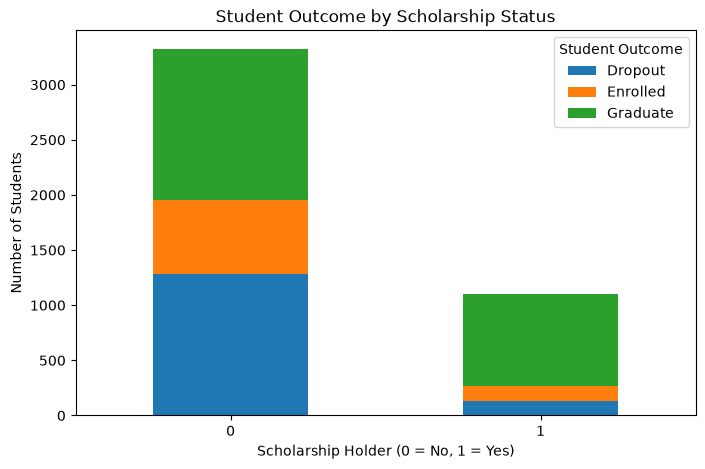

In [114]:
scholarship_analysis = pd.crosstab(
    df['Scholarship holder'],
    df['Target']
)
display(scholarship_analysis)
scholarship_percentage = pd.crosstab(
    df['Scholarship holder'],
    df['Target'],
    normalize='index'
) * 100

display(scholarship_percentage.round(2))

scholarship_analysis.plot(
    kind='bar',
    stacked=True,
    figsize=(8, 5)
)

plt.title('Student Outcome by Scholarship Status')
plt.xlabel('Scholarship Holder (0 = No, 1 = Yes)')
plt.ylabel('Number of Students')
plt.legend(title='Student Outcome')
plt.xticks(rotation=0)
plt.show()

Target,Dropout,Enrolled,Graduate
Debtor,,,
0,1109,704,2108
1,312,90,101


Target,Dropout,Enrolled,Graduate
Debtor,,,
0,28.28,17.95,53.76
1,62.03,17.89,20.08


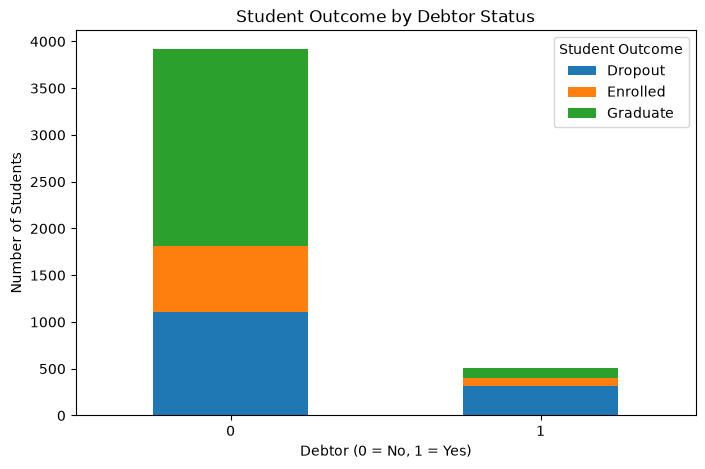

In [115]:
debtor_analysis = pd.crosstab(
    df['Debtor'],
    df['Target']
)

display(debtor_analysis)
debtor_percentage = pd.crosstab(
    df['Debtor'],
    df['Target'],
    normalize='index'
) * 100

display(debtor_percentage.round(2))

debtor_analysis.plot(
    kind='bar',
    stacked=True,
    figsize=(8, 5)
)

plt.title('Student Outcome by Debtor Status')
plt.xlabel('Debtor (0 = No, 1 = Yes)')
plt.ylabel('Number of Students')
plt.legend(title='Student Outcome')
plt.xticks(rotation=0)
plt.show()


Student Count:


Target,Dropout,Enrolled,Graduate
Tuition fees up to date,,,
0,457,42,29
1,964,752,2180



Percentage Distribution:


Target,Dropout,Enrolled,Graduate
Tuition fees up to date,,,
0,86.55,7.95,5.49
1,24.74,19.30,55.95


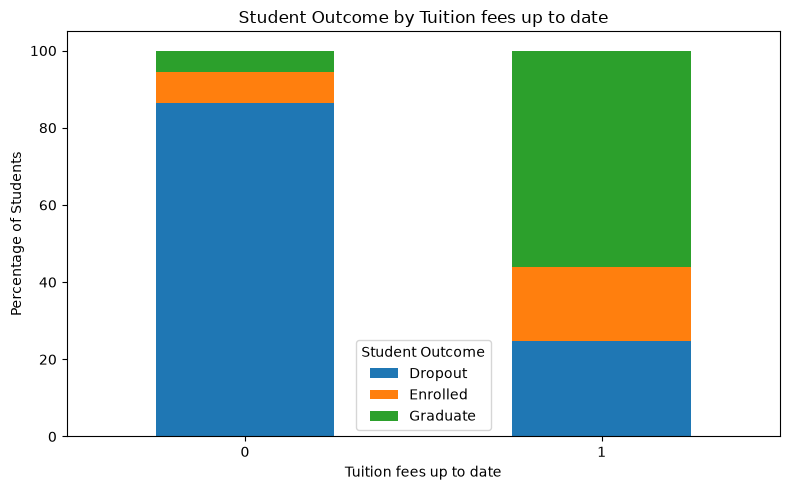


Student Count:


Target,Dropout,Enrolled,Graduate
Gender,,,
0,720,487,1661
1,701,307,548



Percentage Distribution:


Target,Dropout,Enrolled,Graduate
Gender,,,
0,25.10,16.98,57.91
1,45.05,19.73,35.22


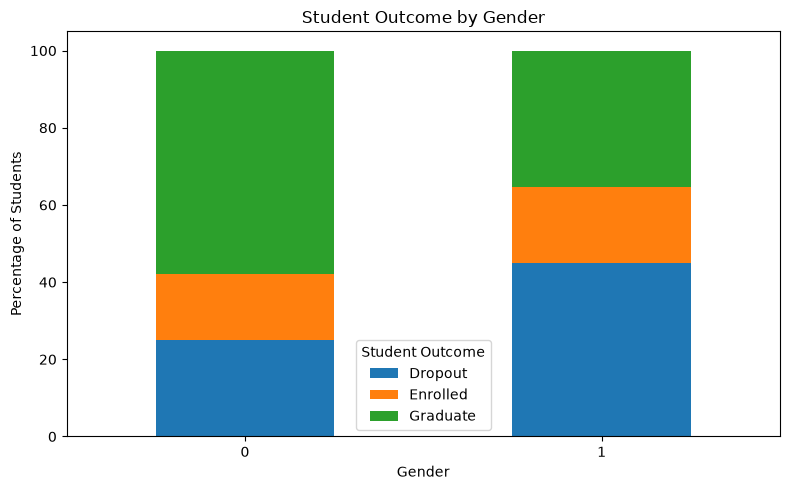


Student Count:


Target,Dropout,Enrolled,Graduate
Daytime/evening attendance,,,
0,207,75,201
1,1214,719,2008



Percentage Distribution:


Target,Dropout,Enrolled,Graduate
Daytime/evening attendance,,,
0,42.86,15.53,41.61
1,30.80,18.24,50.95


C:\Users\shash\AppData\Local\Temp\ipykernel_9984\2033697696.py:34: UserWarning: Glyph 9 (	) missing from font(s) DejaVu Sans.
  plt.tight_layout()
C:\Users\shash\Anaconda\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 9 (	) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


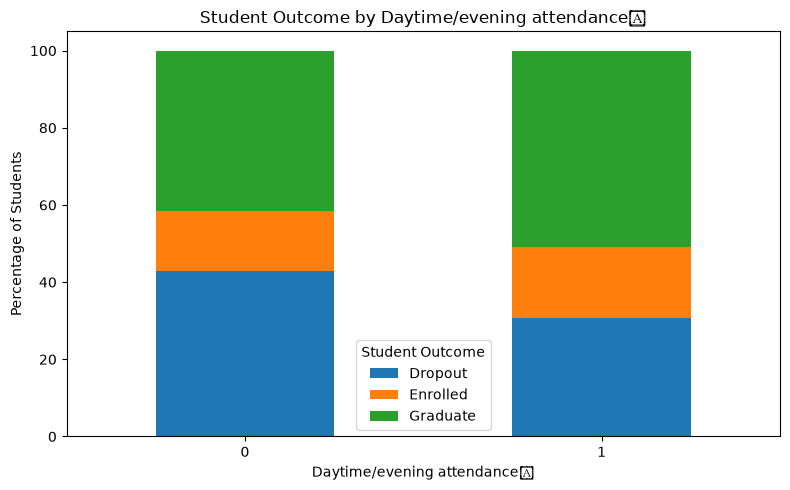

In [116]:
categorical_cols = [
    'Tuition fees up to date',
    'Gender',
    'Daytime/evening attendance\t'
]
for col in categorical_cols:
    count_table = pd.crosstab(
        df[col],
        df['Target']
    )
    print("\nStudent Count:")
    display(count_table)

    percentage_table = pd.crosstab(
        df[col],
        df['Target'],
        normalize='index'
    ) * 100

    print("\nPercentage Distribution:")
    display(percentage_table.round(2))

    percentage_table.plot(
        kind='bar',
        stacked=True,
        figsize=(8, 5)
    )

    plt.title(f'Student Outcome by {col}')
    plt.xlabel(col)
    plt.ylabel('Percentage of Students')
    plt.legend(title='Student Outcome')
    plt.xticks(rotation=0)
    plt.tight_layout()
    plt.show()

In [117]:
correlation = df[continuous_cols].corr()

display(correlation.round(2))

,Previous qualification (grade),Admission grade,Age at enrollment,Curricular units 1st sem (grade),Curricular units 2nd sem (grade),Unemployment rate,Inflation rate,GDP
Previous qualification (grade),1.00,0.58,-0.11,0.06,0.05,0.05,0.02,-0.05
Admission grade,0.58,1.00,-0.03,0.07,0.07,0.04,-0.02,-0.02
Age at enrollment,-0.11,-0.03,1.00,-0.16,-0.17,0.03,0.03,-0.06
Curricular units 1st sem (grade),0.06,0.07,-0.16,1.00,0.84,0.01,-0.03,0.05
Curricular units 2nd sem (grade),0.05,0.07,-0.17,0.84,1.00,0.00,-0.04,0.07
Unemployment rate,0.05,0.04,0.03,0.01,0.00,1.00,-0.03,-0.34
Inflation rate,0.02,-0.02,0.03,-0.03,-0.04,-0.03,1.00,-0.11
GDP,-0.05,-0.02,-0.06,0.05,0.07,-0.34,-0.11,1.00


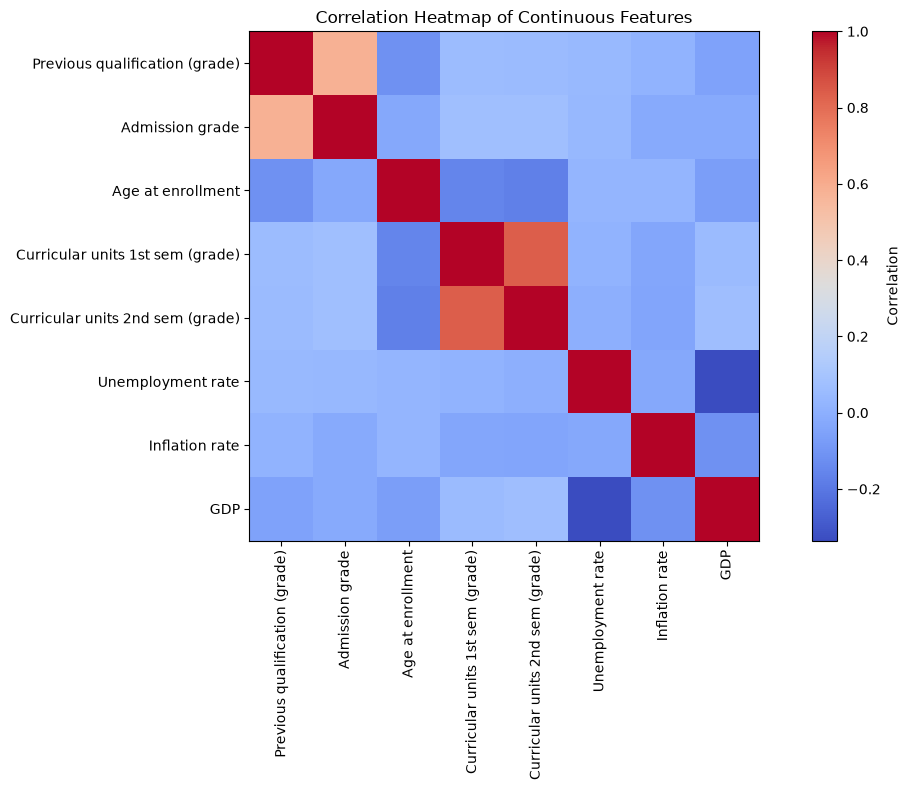

In [118]:
plt.figure(figsize=(12, 8))
plt.imshow(correlation, cmap='coolwarm', interpolation='nearest')
plt.colorbar(label='Correlation')
plt.xticks(
    range(len(correlation.columns)),
    correlation.columns,
    rotation=90
)
plt.yticks(
    range(len(correlation.columns)),
    correlation.columns
)
plt.title('Correlation Heatmap of Continuous Features')
plt.tight_layout()
plt.show()

In [119]:
print("EDA SUMMARY")
print("\n1. Dataset Shape:")
print(df.shape)
print("\n2. Missing Values:")
print(df.isnull().sum().sum())
print("\n3. Duplicate Rows:")
print(df.duplicated().sum())
print("\n4. Target Distribution:")
print(df['Target'].value_counts())
print("\n5. Target Percentage:")
print(
    (df['Target'].value_counts(normalize=True) * 100).round(2)
)
print("\n6. Numerical Features:")
print(continuous_cols)
print("\n7. Correlation Matrix:")
display(correlation.round(2))

EDA SUMMARY

1. Dataset Shape:
(4424, 37)

2. Missing Values:
0

3. Duplicate Rows:
0

4. Target Distribution:
Target
Graduate    2209
Dropout     1421
Enrolled     794
Name: count, dtype: int64

5. Target Percentage:
Target
Graduate    49.93
Dropout     32.12
Enrolled    17.95
Name: proportion, dtype: float64

6. Numerical Features:
['Previous qualification (grade)', 'Admission grade', 'Age at enrollment', 'Curricular units 1st sem (grade)', 'Curricular units 2nd sem (grade)', 'Unemployment rate', 'Inflation rate', 'GDP']

7. Correlation Matrix:


,Previous qualification (grade),Admission grade,Age at enrollment,Curricular units 1st sem (grade),Curricular units 2nd sem (grade),Unemployment rate,Inflation rate,GDP
Previous qualification (grade),1.00,0.58,-0.11,0.06,0.05,0.05,0.02,-0.05
Admission grade,0.58,1.00,-0.03,0.07,0.07,0.04,-0.02,-0.02
Age at enrollment,-0.11,-0.03,1.00,-0.16,-0.17,0.03,0.03,-0.06
Curricular units 1st sem (grade),0.06,0.07,-0.16,1.00,0.84,0.01,-0.03,0.05
Curricular units 2nd sem (grade),0.05,0.07,-0.17,0.84,1.00,0.00,-0.04,0.07
Unemployment rate,0.05,0.04,0.03,0.01,0.00,1.00,-0.03,-0.34
Inflation rate,0.02,-0.02,0.03,-0.03,-0.04,-0.03,1.00,-0.11
GDP,-0.05,-0.02,-0.06,0.05,0.07,-0.34,-0.11,1.00


In [120]:
#starting preprocessing now
df.columns = df.columns.str.strip()
feature_cols = [
    'Marital status','Application mode','Application order','Course','Daytime/evening attendance','Previous qualification','Previous qualification (grade)','Nacionality',"Mother's qualification","Father's qualification","Mother's occupation","Father's occupation",'Admission grade','Displaced','Educational special needs','Debtor','Tuition fees up to date','Gender','Scholarship holder','Age at enrollment','International','Curricular units 1st sem (credited)','Curricular units 1st sem (enrolled)','Curricular units 1st sem (evaluations)','Curricular units 1st sem (approved)','Curricular units 1st sem (grade)','Curricular units 1st sem (without evaluations)','Unemployment rate','Inflation rate','GDP'
]

missing_features = [col for col in feature_cols if col not in df.columns]
print("Missing features:", missing_features)

X = df[feature_cols]
y = df['Target']

print("\nFeatures shape:", X.shape)
print("Target shape:", y.shape)

display(X.head())
display(y.head())

Missing features: []

Features shape: (4424, 30)
Target shape: (4424,)


,Marital status,Application mode,Application order,Course,Daytime/evening attendance,Previous qualification,Previous qualification (grade),Nacionality,Mother's qualification,Father's qualification,Mother's occupation,Father's occupation,Admission grade,Displaced,Educational special needs,Debtor,Tuition fees up to date,Gender,Scholarship holder,Age at enrollment,International,Curricular units 1st sem (credited),Curricular units 1st sem (enrolled),Curricular units 1st sem (evaluations),Curricular units 1st sem (approved),Curricular units 1st sem (grade),Curricular units 1st sem (without evaluations),Unemployment rate,Inflation rate,GDP
0,1,17,5,171,1,1,122.0,1,19,12,5,9,127.3,1,0,0,1,1,0,20,0,0,0,0,0,0.000000,0,10.8,1.4,1.74
1,1,15,1,9254,1,1,160.0,1,1,3,3,3,142.5,1,0,0,0,1,0,19,0,0,6,6,6,14.000000,0,13.9,-0.3,0.79
2,1,1,5,9070,1,1,122.0,1,37,37,9,9,124.8,1,0,0,0,1,0,19,0,0,6,0,0,0.000000,0,10.8,1.4,1.74
3,1,17,2,9773,1,1,122.0,1,38,37,5,3,119.6,1,0,0,1,0,0,20,0,0,6,8,6,13.428571,0,9.4,-0.8,-3.12
4,2,39,1,8014,0,1,100.0,1,37,38,9,9,141.5,0,0,0,1,0,0,45,0,0,6,9,5,12.333333,0,13.9,-0.3,0.79


0     Dropout
1    Graduate
2     Dropout
3    Graduate
4    Graduate
Name: Target, dtype: str

In [121]:
categorical_cols = [
    'Marital status',
    'Application mode',
    'Course',
    'Daytime/evening attendance',
    'Previous qualification',
    'Nacionality',
    "Mother's qualification",
    "Father's qualification",
    "Mother's occupation",
    "Father's occupation"
]

print("Categorical columns:")
for col in categorical_cols:
    print(col, ":", X[col].nunique(), "unique categories")

Categorical columns:
Marital status : 6 unique categories
Application mode : 18 unique categories
Course : 17 unique categories
Daytime/evening attendance : 2 unique categories
Previous qualification : 17 unique categories
Nacionality : 21 unique categories
Mother's qualification : 29 unique categories
Father's qualification : 34 unique categories
Mother's occupation : 32 unique categories
Father's occupation : 46 unique categories


In [122]:
numerical_cols = [
    col for col in feature_cols
    if col not in categorical_cols
]
print("Numerical columns:")
print(numerical_cols)

print("\nTotal numerical columns:", len(numerical_cols))
print("Total categorical columns:", len(categorical_cols))
print("Numerical features shape:", X[numerical_cols].shape)
print("Categorical features shape:", X[categorical_cols].shape)

Numerical columns:
['Application order', 'Previous qualification (grade)', 'Admission grade', 'Displaced', 'Educational special needs', 'Debtor', 'Tuition fees up to date', 'Gender', 'Scholarship holder', 'Age at enrollment', 'International', 'Curricular units 1st sem (credited)', 'Curricular units 1st sem (enrolled)', 'Curricular units 1st sem (evaluations)', 'Curricular units 1st sem (approved)', 'Curricular units 1st sem (grade)', 'Curricular units 1st sem (without evaluations)', 'Unemployment rate', 'Inflation rate', 'GDP']

Total numerical columns: 20
Total categorical columns: 10
Numerical features shape: (4424, 20)
Categorical features shape: (4424, 10)


In [123]:
X_train, X_test, y_train, y_test = train_test_split(X,y,test_size=0.2,random_state=42,stratify=y)

print("X_train shape:", X_train.shape)
print("X_test shape:", X_test.shape)
print("y_train shape:", y_train.shape)
print("y_test shape:", y_test.shape)

X_train shape: (3539, 30)
X_test shape: (885, 30)
y_train shape: (3539,)
y_test shape: (885,)


In [124]:
preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), numerical_cols),
        ('cat', OneHotEncoder(handle_unknown='ignore'), categorical_cols)
    ]
)
X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)

print("Processed training shape:", X_train_processed.shape)
print("Processed testing shape:", X_test_processed.shape)

Processed training shape: (3539, 231)
Processed testing shape: (885, 231)


In [125]:
#starting classification
model = Pipeline([
    ('preprocessor', preprocessor),
    ('classifier', LogisticRegression(max_iter=1000))
])
model.fit(X_train, y_train)
y_pred = model.predict(X_test)
print("First 10 Predictions:")
print(y_pred[:10])
comparison = pd.DataFrame({
    'Actual Outcome': y_test.values,
    'Predicted Outcome': y_pred
})

comparison.head(10)

First 10 Predictions:
['Graduate' 'Graduate' 'Enrolled' 'Graduate' 'Graduate' 'Graduate'
 'Graduate' 'Graduate' 'Graduate' 'Graduate']


,Actual Outcome,Predicted Outcome
0,Graduate,Graduate
1,Graduate,Graduate
2,Enrolled,Enrolled
3,Graduate,Graduate
4,Graduate,Graduate
5,Graduate,Graduate
6,Graduate,Graduate
7,Graduate,Graduate
8,Graduate,Graduate
9,Graduate,Graduate


Model Accuracy: 0.7491525423728813
Model Accuracy (%): 74.91525423728814
              precision    recall  f1-score   support

     Dropout       0.80      0.75      0.77       284
    Enrolled       0.49      0.33      0.40       159
    Graduate       0.78      0.90      0.83       442

    accuracy                           0.75       885
   macro avg       0.69      0.66      0.67       885
weighted avg       0.73      0.75      0.74       885



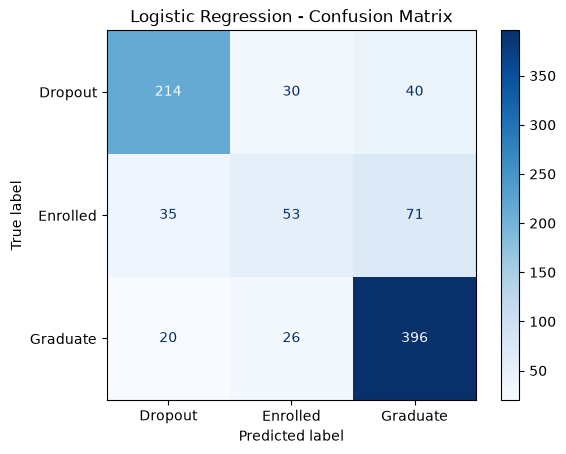

In [126]:
accuracy = accuracy_score(y_test, y_pred)
print("Model Accuracy:", accuracy)
print("Model Accuracy (%):", accuracy * 100)
print(classification_report(y_test, y_pred))

cm = confusion_matrix(
    y_test,
    y_pred,
    labels=model.classes_
)

display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=model.classes_
)

display.plot(cmap='Blues')
plt.title('Logistic Regression - Confusion Matrix')
plt.show()

In [127]:
model_weighted = Pipeline([
    ('preprocessor', preprocessor),
    ('classifier', LogisticRegression(
        max_iter=1000,
        class_weight='balanced'
    ))
])
model_weighted.fit(X_train, y_train)
y_pred_weighted = model_weighted.predict(X_test)
print("Weighted Model Accuracy:",
      accuracy_score(y_test, y_pred_weighted))
print("\nWeighted Classification Report:\n")
print(classification_report(y_test, y_pred_weighted))

Weighted Model Accuracy: 0.6994350282485876

Weighted Classification Report:

              precision    recall  f1-score   support

     Dropout       0.78      0.68      0.73       284
    Enrolled       0.38      0.56      0.46       159
    Graduate       0.83      0.76      0.79       442

    accuracy                           0.70       885
   macro avg       0.67      0.67      0.66       885
weighted avg       0.73      0.70      0.71       885



In [128]:
comparison_results = pd.DataFrame({
    'Model': ['Original Logistic Regression',
              'Weighted Logistic Regression'],
    'Accuracy': [
        accuracy_score(y_test, y_pred),
        accuracy_score(y_test, y_pred_weighted)
    ],
    'Macro F1': [
        0.67,
        0.66
    ],
    'Weighted F1': [
        0.74,
        0.71
    ]
})
comparison_results.round(3)

,Model,Accuracy,Macro F1,Weighted F1
0,Original Logistic Regression,0.749,0.67,0.74
1,Weighted Logistic Regression,0.699,0.66,0.71


In [129]:
df['Dropout_Flag'] = (df['Target'] == 'Dropout').astype(int)

print(df['Dropout_Flag'].value_counts())

Dropout_Flag
0    3003
1    1421
Name: count, dtype: int64


In [130]:
X_binary = df[feature_cols]
y_binary = df['Dropout_Flag']

print("Features shape:", X_binary.shape)
print("Target shape:", y_binary.shape)

y_binary.value_counts()

Features shape: (4424, 30)
Target shape: (4424,)


Dropout_Flag
0    3003
1    1421
Name: count, dtype: int64

In [134]:
X_train_bin, X_test_bin, y_train_bin, y_test_bin = train_test_split(X_binary,y_binary,test_size=0.2,random_state=42,stratify=y_binary)
print("Training Features:", X_train_bin.shape)
print("Testing Features:", X_test_bin.shape)
print("Training Target:", y_train_bin.shape)
print("Testing Target:", y_test_bin.shape)
preprocessor_bin = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), numerical_cols),
        ('cat', OneHotEncoder(handle_unknown='ignore'), categorical_cols)
    ])
X_train_bin_processed = preprocessor_bin.fit_transform(X_train_bin)
X_test_bin_processed = preprocessor_bin.transform(X_test_bin)
print("Processed Training Shape:", X_train_bin_processed.shape)
print("Processed Testing Shape:", X_test_bin_processed.shape)

Training Features: (3539, 30)
Testing Features: (885, 30)
Training Target: (3539,)
Testing Target: (885,)
Processed Training Shape: (3539, 230)
Processed Testing Shape: (885, 230)


In [140]:
binary_model = Pipeline([
    ('preprocessor', preprocessor_bin),
    ('classifier', LogisticRegression(max_iter=1000))
])

binary_model.fit(X_train_bin, y_train_bin)
y_pred_bin = binary_model.predict(X_test_bin)
print("First 10 Actual Values:")
print(y_test_bin[:10].values)
print("\nFirst 10 Predicted Values:")
print(y_pred_bin[:10])
print("Binary Model Accuracy:",
      accuracy_score(y_test_bin, y_pred_bin))
print("\nClassification Report:\n")
print(classification_report(
    y_test_bin,
    y_pred_bin,
    target_names=['Not Dropout', 'Dropout']
))

First 10 Actual Values:
[0 0 1 0 1 0 1 1 0 1]

First 10 Predicted Values:
[0 0 1 0 1 0 1 0 0 1]
Binary Model Accuracy: 0.8655367231638418

Classification Report:

              precision    recall  f1-score   support

 Not Dropout       0.87      0.94      0.91       601
     Dropout       0.85      0.70      0.77       284

    accuracy                           0.87       885
   macro avg       0.86      0.82      0.84       885
weighted avg       0.86      0.87      0.86       885



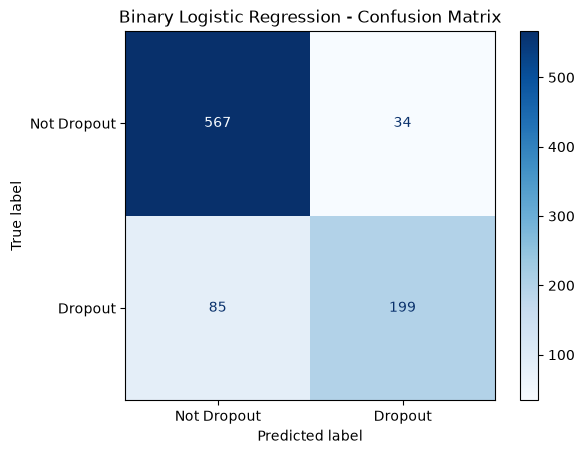

In [141]:
cm_bin = confusion_matrix(
    y_test_bin,
    y_pred_bin,
    labels=[0, 1]
)
cm_bin_display = ConfusionMatrixDisplay(
    confusion_matrix=cm_bin,
    display_labels=['Not Dropout', 'Dropout']
)
cm_bin_display.plot(cmap='Blues')
plt.title('Binary Logistic Regression - Confusion Matrix')
plt.show()

In [142]:
regression_target = 'Curricular units 2nd sem (grade)'

y_reg = df[regression_target]

print("Target Shape:", y_reg.shape)
print("\nFirst 10 Target Values:")
print(y_reg.head(10))

Target Shape: (4424,)

First 10 Target Values:
0     0.000000
1    13.666667
2     0.000000
3    12.400000
4    13.000000
5    11.500000
6    14.345000
7     0.000000
8    14.142857
9    13.500000
Name: Curricular units 2nd sem (grade), dtype: float64


In [146]:
X_reg = df[feature_cols]
print("Features Shape:", X_reg.shape)
print("Target Shape:", y_reg.shape)
X_train_reg, X_test_reg, y_train_reg, y_test_reg = train_test_split(X_reg,y_reg,test_size=0.2,random_state=42)
print("Training Features:", X_train_reg.shape)
print("Testing Features:", X_test_reg.shape)
print("Training Target:", y_train_reg.shape)
print("Testing Target:", y_test_reg.shape)

Features Shape: (4424, 30)
Target Shape: (4424,)
Training Features: (3539, 30)
Testing Features: (885, 30)
Training Target: (3539,)
Testing Target: (885,)


In [148]:
preprocessor_reg = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), numerical_cols),
        ('cat', OneHotEncoder(handle_unknown='ignore'), categorical_cols)
    ])
X_train_reg_processed = preprocessor_reg.fit_transform(X_train_reg)
X_test_reg_processed = preprocessor_reg.transform(X_test_reg)
print("Processed Training Shape:", X_train_reg_processed.shape)
print("Processed Testing Shape:", X_test_reg_processed.shape)

Processed Training Shape: (3539, 236)
Processed Testing Shape: (885, 236)


In [153]:
reg_model = Pipeline([
    ('preprocessor', preprocessor_reg),
    ('regressor', LinearRegression())
])
reg_model.fit(X_train_reg, y_train_reg)

y_pred_reg = reg_model.predict(X_test_reg)
print("First 10 Actual Grades:")
print(y_test_reg.head(10).values)
print("\nFirst 10 Predicted Grades:")
print(y_pred_reg[:10])

First 10 Actual Grades:
[10.         12.14285714 12.28571429 13.          0.         11.5
 12.5        13.875      14.34125    14.67142857]

First 10 Predicted Grades:
[ 1.58097626 11.60787675 12.51571644 13.19698578  1.87045193 10.24322033
 11.74603454 14.7924874  14.29524084 14.4621876 ]


In [156]:
mae = mean_absolute_error(y_test_reg, y_pred_reg)
mse = mean_squared_error(y_test_reg, y_pred_reg)
rmse = np.sqrt(mse)
r2 = r2_score(y_test_reg, y_pred_reg)
print("Mean Absolute Error (MAE):", mae)
print("Mean Squared Error (MSE):", mse)
print("Root Mean Squared Error (RMSE):", rmse)
print("R2 Score:", r2)

Mean Absolute Error (MAE): 1.6161556157937556
Mean Squared Error (MSE): 7.19132260158404
Root Mean Squared Error (RMSE): 2.6816641477977887
R2 Score: 0.7343821560711817


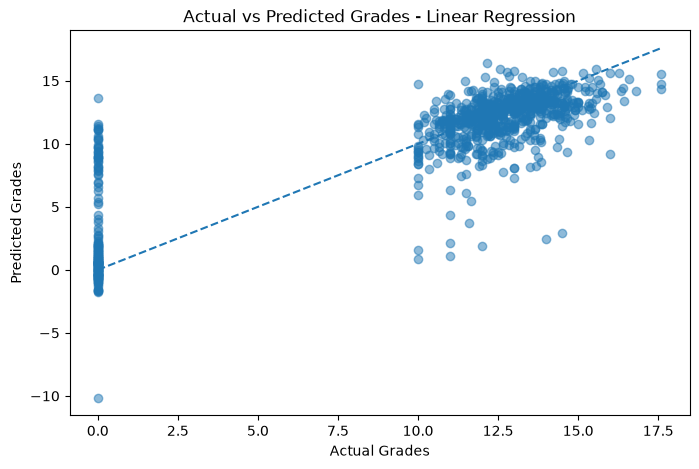

In [157]:
plt.figure(figsize=(8, 5))
plt.scatter(y_test_reg, y_pred_reg, alpha=0.5)
plt.xlabel("Actual Grades")
plt.ylabel("Predicted Grades")
plt.title("Actual vs Predicted Grades - Linear Regression")
plt.plot(
    [y_test_reg.min(), y_test_reg.max()],
    [y_test_reg.min(), y_test_reg.max()],
    linestyle='--'
)
plt.show()

In [159]:
zero_grades = (df[regression_target] == 0).sum()
nonzero_grades = (df[regression_target] > 0).sum()
print("Students with Zero Grades:", zero_grades)
print("Students with Non-Zero Grades:", nonzero_grades)
zero_analysis = df.groupby('Target').agg(
    Total_Students=('Target', 'count'),
    Zero_Grades=(regression_target, lambda x: (x == 0).sum()),
    Non_Zero_Grades=(regression_target, lambda x: (x > 0).sum())
)

zero_analysis['Zero_Percentage'] = (
    zero_analysis['Zero_Grades'] /
    zero_analysis['Total_Students'] * 100
)

zero_analysis.round(2)

Students with Zero Grades: 870
Students with Non-Zero Grades: 3554


,Total_Students,Zero_Grades,Non_Zero_Grades,Zero_Percentage
Target,,,,
Dropout,1421,727,694,51.16
Enrolled,794,68,726,8.56
Graduate,2209,75,2134,3.40


In [161]:
df_reg = df[df[regression_target] > 0].copy()
X_reg = df_reg[feature_cols]
y_reg = df_reg[regression_target]
print("Regression Dataset Shape:", df_reg.shape)
print("Features Shape:", X_reg.shape)
print("Target Shape:", y_reg.shape)
print("Zero Grades:", (y_reg == 0).sum())

X_train_reg2, X_test_reg2, y_train_reg2, y_test_reg2 = train_test_split(
    X_reg,
    y_reg,
    test_size=0.2,
    random_state=42
)
print("Training Features:", X_train_reg2.shape)
print("Testing Features:", X_test_reg2.shape)
print("Training Target:", y_train_reg2.shape)
print("Testing Target:", y_test_reg2.shape)

Regression Dataset Shape: (3554, 38)
Features Shape: (3554, 30)
Target Shape: (3554,)
Zero Grades: 0
Training Features: (2843, 30)
Testing Features: (711, 30)
Training Target: (2843,)
Testing Target: (711,)


In [162]:
preprocessor_reg2 = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), numerical_cols),
        ('cat', OneHotEncoder(handle_unknown='ignore'), categorical_cols)
    ])
X_train_reg2_processed = preprocessor_reg2.fit_transform(X_train_reg2)
X_test_reg2_processed = preprocessor_reg2.transform(X_test_reg2)
print("Processed Training Shape:", X_train_reg2_processed.shape)
print("Processed Testing Shape:", X_test_reg2_processed.shape)

Processed Training Shape: (2843, 218)
Processed Testing Shape: (711, 218)


In [164]:
reg_model2 = Pipeline([
    ('preprocessor', preprocessor_reg2),
    ('regressor', LinearRegression())
])
reg_model2.fit(X_train_reg2, y_train_reg2)

y_pred_reg2 = reg_model2.predict(X_test_reg2)
print("First 10 Actual Grades:")
print(y_test_reg2.head(10).values)
print("\nFirst 10 Predicted Grades:")
print(y_pred_reg2[:10])

First 10 Actual Grades:
[11.83333333 11.         14.575      11.66666667 12.76666667 12.
 13.14285714 12.91111111 15.         13.5       ]

First 10 Predicted Grades:
[12.19611045 12.39675965 13.704998   11.76983428 13.43095711 11.76850549
 12.57564423 13.16137098 13.0243292  14.10030494]


In [165]:
mae_reg2 = mean_absolute_error(y_test_reg2, y_pred_reg2)
mse_reg2 = mean_squared_error(y_test_reg2, y_pred_reg2)
rmse_reg2 = np.sqrt(mse_reg2)
r2_reg2 = r2_score(y_test_reg2, y_pred_reg2)
print("MAE:", mae_reg2)
print("MSE:", mse_reg2)
print("RMSE:", rmse_reg2)
print("R2 Score:", r2_reg2)

MAE: 0.8425013721745266
MSE: 1.1521169253901076
RMSE: 1.073367097217959
R2 Score: 0.37808580942328995


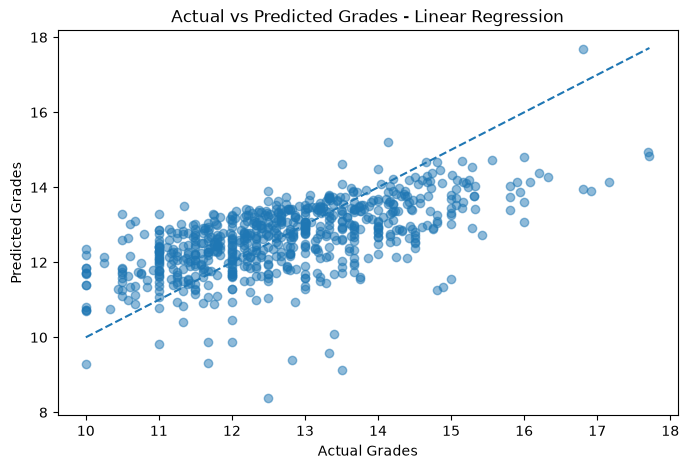

In [166]:
plt.figure(figsize=(8, 5))
plt.scatter(y_test_reg2, y_pred_reg2, alpha=0.5)
plt.xlabel("Actual Grades")
plt.ylabel("Predicted Grades")
plt.title("Actual vs Predicted Grades - Linear Regression")
plt.plot(
    [y_test_reg2.min(), y_test_reg2.max()],
    [y_test_reg2.min(), y_test_reg2.max()],
    linestyle='--'
)
plt.show()

In [170]:
dt_model = Pipeline([
    ('preprocessor', preprocessor_reg2),
    ('regressor', DecisionTreeRegressor(random_state=42))
])
dt_model.fit(X_train_reg2, y_train_reg2)
y_pred_dt = dt_model.predict(X_test_reg2)
print("First 10 Actual Grades:")
print(y_test_reg2.head(10).values)
print("\nFirst 10 Predicted Grades:")
print(y_pred_dt[:10])

First 10 Actual Grades:
[11.83333333 11.         14.575      11.66666667 12.76666667 12.
 13.14285714 12.91111111 15.         13.5       ]

First 10 Predicted Grades:
[12.         12.04285714 14.75       12.         13.         11.9
 11.83333333 13.6        13.16666667 14.14285714]


In [171]:
mae_dt = mean_absolute_error(y_test_reg2, y_pred_dt)
mse_dt = mean_squared_error(y_test_reg2, y_pred_dt)
rmse_dt = np.sqrt(mse_dt)
r2_dt = r2_score(y_test_reg2, y_pred_dt)
print("Decision Tree Regression Results")
print("MAE:", mae_dt)
print("MSE:", mse_dt)
print("RMSE:", rmse_dt)
print("R2 Score:", r2_dt)

Decision Tree Regression Results
MAE: 0.9823061494592925
MSE: 1.6896360730580897
RMSE: 1.299860020563018
R2 Score: 0.08793228570153311


In [172]:
regression_comparison = pd.DataFrame({
    'Model': ['Linear Regression', 'Decision Tree'],
    'MAE': [mae_reg2, mae_dt],
    'MSE': [mse_reg2, mse_dt],
    'RMSE': [rmse_reg2, rmse_dt],
    'R2 Score': [r2_reg2, r2_dt]
})
regression_comparison.round(3)

,Model,MAE,MSE,RMSE,R2 Score
0,Linear Regression,0.843,1.152,1.073,0.378
1,Decision Tree,0.982,1.690,1.300,0.088


In [177]:
rf_model = Pipeline([
    ('preprocessor', preprocessor_reg2),
    ('regressor', RandomForestRegressor(
        n_estimators=100,
        random_state=42
    ))
])
rf_model.fit(X_train_reg2, y_train_reg2)
y_pred_rf = rf_model.predict(X_test_reg2)
print("First 10 Actual Grades:")
print(y_test_reg2.head(10).values)
print("\nFirst 10 Predicted Grades:")
print(y_pred_rf[:10])

First 10 Actual Grades:
[11.83333333 11.         14.575      11.66666667 12.76666667 12.
 13.14285714 12.91111111 15.         13.5       ]

First 10 Predicted Grades:
[12.13736667 11.85481336 14.17843696 11.86237592 12.78921766 12.1816795
 12.69100738 12.86713649 13.66994048 13.79197143]


In [178]:
mae_rf = mean_absolute_error(y_test_reg2, y_pred_rf)
mse_rf = mean_squared_error(y_test_reg2, y_pred_rf)
rmse_rf = np.sqrt(mse_rf)
r2_rf = r2_score(y_test_reg2, y_pred_rf)
print("Random Forest Regression Results")
print("MAE:", mae_rf)
print("MSE:", mse_rf)
print("RMSE:", rmse_rf)
print("R2 Score:", r2_rf)

Random Forest Regression Results
MAE: 0.7128716587312071
MSE: 0.8638926884331866
RMSE: 0.9294582768651783
R2 Score: 0.533669621344948


In [179]:
regression_comparison = pd.DataFrame({
    'Model': [
        'Linear Regression',
        'Decision Tree',
        'Random Forest'
    ],
    'MAE': [mae_reg2, mae_dt, mae_rf],
    'MSE': [mse_reg2, mse_dt, mse_rf],
    'RMSE': [rmse_reg2, rmse_dt, rmse_rf],
    'R2 Score': [r2_reg2, r2_dt, r2_rf]
})
regression_comparison.round(3)

,Model,MAE,MSE,RMSE,R2 Score
0,Linear Regression,0.843,1.152,1.073,0.378
1,Decision Tree,0.982,1.690,1.300,0.088
2,Random Forest,0.713,0.864,0.929,0.534


In [186]:
param_grid = {
    'regressor__n_estimators': [100, 200],
    'regressor__max_depth': [None, 10, 20],
    'regressor__min_samples_split': [2, 5]
}
grid_search = GridSearchCV(
    estimator=rf_model,
    param_grid=param_grid,
    cv=2,
    scoring='r2',
    n_jobs=-1,
    verbose=1
)
grid_search.fit(X_train_reg2, y_train_reg2)
print("Best Parameters:")
print(grid_search.best_params_)

print("\nBest Cross-Validation R2 Score:")
print(grid_search.best_score_)

Fitting 2 folds for each of 12 candidates, totalling 24 fits
Best Parameters:
{'regressor__max_depth': 10, 'regressor__min_samples_split': 5, 'regressor__n_estimators': 200}

Best Cross-Validation R2 Score:
0.48906196359434995


In [189]:
best_rf_model = grid_search.best_estimator_
y_pred_best_rf = best_rf_model.predict(X_test_reg2)
mae_best_rf = mean_absolute_error(y_test_reg2, y_pred_best_rf)
mse_best_rf = mean_squared_error(y_test_reg2, y_pred_best_rf)
rmse_best_rf = np.sqrt(mse_best_rf)
r2_best_rf = r2_score(y_test_reg2, y_pred_best_rf)
print("Tuned Random Forest Results")
print("MAE:", mae_best_rf)
print("MSE:", mse_best_rf)
print("RMSE:", rmse_best_rf)
print("R2 Score:", r2_best_rf)

Tuned Random Forest Results
MAE: 0.714858295777207
MSE: 0.8707278007693091
RMSE: 0.9331279659132016
R2 Score: 0.5299800189596856


In [193]:
multiclass_comparison = pd.DataFrame({
    'Model': ['Original Logistic Regression', 'Weighted Logistic Regression'],
    'Accuracy': [
        accuracy_score(y_test, y_pred),
        accuracy_score(y_test, y_pred_weighted)
    ],
    'Macro F1': [
        f1_score(y_test, y_pred, average='macro'),
        f1_score(y_test, y_pred_weighted, average='macro')
    ],
    'Weighted F1': [
        f1_score(y_test, y_pred, average='weighted'),
        f1_score(y_test, y_pred_weighted, average='weighted')
    ],
    'Enrolled Recall': [
        recall_score(y_test, y_pred, labels=['Enrolled'], average=None)[0],
        recall_score(y_test, y_pred_weighted, labels=['Enrolled'], average=None)[0]
    ]
})
multiclass_comparison.round(3)

,Model,Accuracy,Macro F1,Weighted F1,Enrolled Recall
0,Original Logistic Regression,0.749,0.668,0.736,0.333
1,Weighted Logistic Regression,0.699,0.659,0.712,0.560


In [196]:
binary_results = pd.DataFrame({
    'Metric': ['Accuracy', 'Precision', 'Recall', 'F1 Score'],
    'Score': [
        accuracy_score(y_test_bin, y_pred_bin),
        precision_score(y_test_bin, y_pred_bin),
        recall_score(y_test_bin, y_pred_bin),
        f1_score(y_test_bin, y_pred_bin)
    ]
})
binary_results.round(3)

,Metric,Score
0,Accuracy,0.866
1,Precision,0.854
2,Recall,0.701
3,F1 Score,0.770


In [197]:
regression_comparison_final = pd.DataFrame({
    'Model': [
        'Linear Regression',
        'Decision Tree',
        'Random Forest',
        'Tuned Random Forest'
    ],
    'MAE': [
        mae_reg2, mae_dt, mae_rf, mae_best_rf
    ],
    'MSE': [
        mse_reg2, mse_dt, mse_rf, mse_best_rf
    ],
    'RMSE': [
        rmse_reg2, rmse_dt, rmse_rf, rmse_best_rf
    ],
    'R2 Score': [
        r2_reg2, r2_dt, r2_rf, r2_best_rf
    ]
})
regression_comparison_final.round(3)

,Model,MAE,MSE,RMSE,R2 Score
0,Linear Regression,0.843,1.152,1.073,0.378
1,Decision Tree,0.982,1.690,1.300,0.088
2,Random Forest,0.713,0.864,0.929,0.534
3,Tuned Random Forest,0.715,0.871,0.933,0.530


In [199]:
import joblib
joblib.dump(model, 'multiclass_model.pkl')
joblib.dump(binary_model, 'binary_model.pkl')
joblib.dump(rf_model, 'regression_model.pkl')
print("All three models saved successfully!")

All three models saved successfully!
